1. Promedio de productos pedidos por dia de la semana.

    Calcular el promedio de productos por dia de la semanan y ordenalos de lunesa viernes, muestra los resultados en un grafico de barras verticales(asigna los colores para cada barra)) para identificar que dia se pierden mas productos en promedio.
2. Crear una nueva columna de nombre URGENCIA ue contenga ranngos de urgencia por dias:

    1-2 = Urgente
    3-4 = Normal
    5-10= Sin urgencia

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
pedidos = pd.read_csv('pedidos_limpio.csv')

**PREGUNTA 1**

Promedio de productos por pedido:
dia_semana
lunes        19.23
martes       20.06
miércoles    16.30
jueves        9.57
viernes       9.52
Name: num_productos, dtype: float64


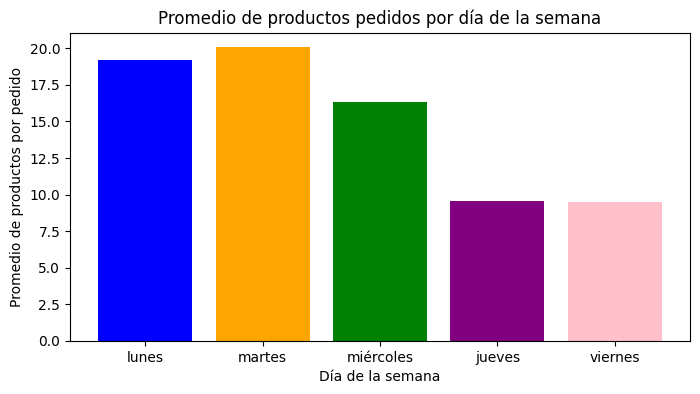

In [4]:
dias = ['lunes', 'martes', 'miércoles', 'jueves', 'viernes']

promedios = pedidos.groupby('dia_semana')['num_productos'].mean()
promedios = promedios.reindex(dias)

print('Promedio de productos por pedido:')
print(promedios.round(2))

colores = ['blue', 'orange', 'green', 'purple', 'pink']

plt.figure(figsize=(8, 4))
plt.bar(promedios.index, promedios, color=colores)
plt.title('Promedio de productos pedidos por día de la semana')
plt.xlabel('Día de la semana')
plt.ylabel('Promedio de productos por pedido')
plt.show()

**PREGUNTA 2**

In [5]:
rangos = [0, 2, 4, 10]
etiquetas = ['Urgente', 'Normal', 'Sin urgencia']

pedidos['URGENCIA'] = pd.cut(
    pedidos['tiempo_entrega_previsto'],
    bins=rangos,
    labels=etiquetas
)

print('\nPrimeros pedidos clasificados:')
print(pedidos[['tiempo_entrega_previsto', 'URGENCIA']].head(10))

print('\nCantidad de pedidos por nivel de urgencia:')
print(pedidos['URGENCIA'].value_counts())


Primeros pedidos clasificados:
   tiempo_entrega_previsto      URGENCIA
0                        4        Normal
1                        2       Urgente
2                        2       Urgente
3                        2       Urgente
4                        5  Sin urgencia
5                        3        Normal
6                        5  Sin urgencia
7                        5  Sin urgencia
8                        1       Urgente
9                        2       Urgente

Cantidad de pedidos por nivel de urgencia:
URGENCIA
Urgente         44
Normal          35
Sin urgencia    21
Name: count, dtype: int64
